In [18]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf
from arch import arch_model
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [20]:
# Any Yahoo Finance symbol. Everything below uses this value.
ticker = "AAPL"
start = "2022-01-01"
# yfinance treats end as exclusive, so tomorrow includes the day this cell is run.
end = pd.Timestamp.today().normalize() + pd.Timedelta(days=1)

df = yf.download(ticker, start=start, end=end, progress=False)
if df.empty:
    raise ValueError(f"No price data returned for {ticker}")

close = df["Close"]
prices = close.iloc[:, 0] if isinstance(close, pd.DataFrame) else close
prices = prices.dropna()
prices.name = ticker

try:
    currency = yf.Ticker(ticker).fast_info.currency or ""
except Exception:
    currency = ""

diff_prices = prices.diff().dropna()
returns = prices.pct_change().dropna() * 100

log_returns = np.log(prices / prices.shift(1)).dropna() * 100
log_returns.name = ticker

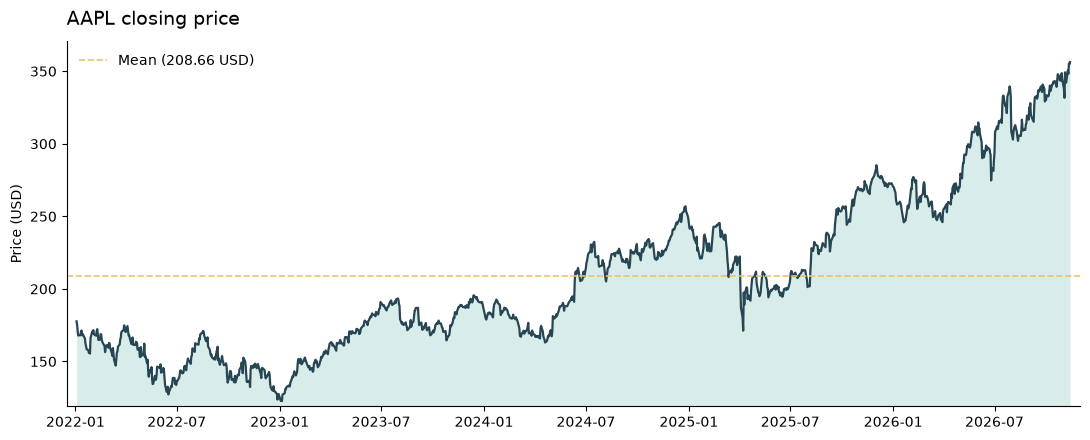

In [21]:
fig, ax = plt.subplots(figsize=(11, 4.5))

floor = float(prices.min()) * 0.97
ax.fill_between(prices.index, prices, floor, color="#2a9d8f", alpha=0.18, linewidth=0)
ax.plot(prices.index, prices, color="#264653", linewidth=1.6)

mean = float(prices.mean())
mean_label = f"Mean ({mean:,.2f} {currency})" if currency else f"Mean ({mean:,.2f})"
ax.axhline(
    mean,
    color="#e9c46a",
    linewidth=1.2,
    linestyle="--",
    label=mean_label,
)

ax.set_title(f"{ticker} closing price", loc="left", fontsize=14, pad=12)
ax.set_ylabel(f"Price ({currency})" if currency else "Price")
ax.set_ylim(floor, float(prices.max()) * 1.04)
ax.legend(frameon=False, loc="upper left")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.margins(x=0.01)
fig.tight_layout()
plt.show()

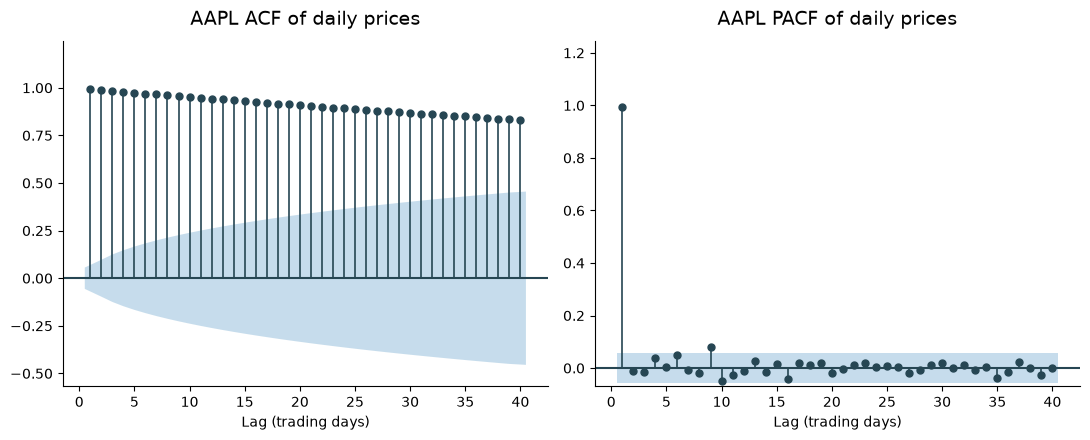

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
stem = {"colors": "#264653", "linewidth": 1.2}

plot_acf(
    prices,
    lags=40,
    ax=axes[0],
    zero=False,
    auto_ylims=True,
    title=f"{ticker} ACF of daily prices",
    color="#264653",
    vlines_kwargs=stem,
)
plot_pacf(
    prices,
    lags=40,
    ax=axes[1],
    method="ywm",
    zero=False,
    auto_ylims=True,
    title=f"{ticker} PACF of daily prices",
    color="#264653",
    vlines_kwargs=stem,
)
for ax in axes:
    ax.set_title(ax.get_title(), fontsize=14, pad=12)
    ax.set_xlabel("Lag (trading days)")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.tight_layout()
plt.show()

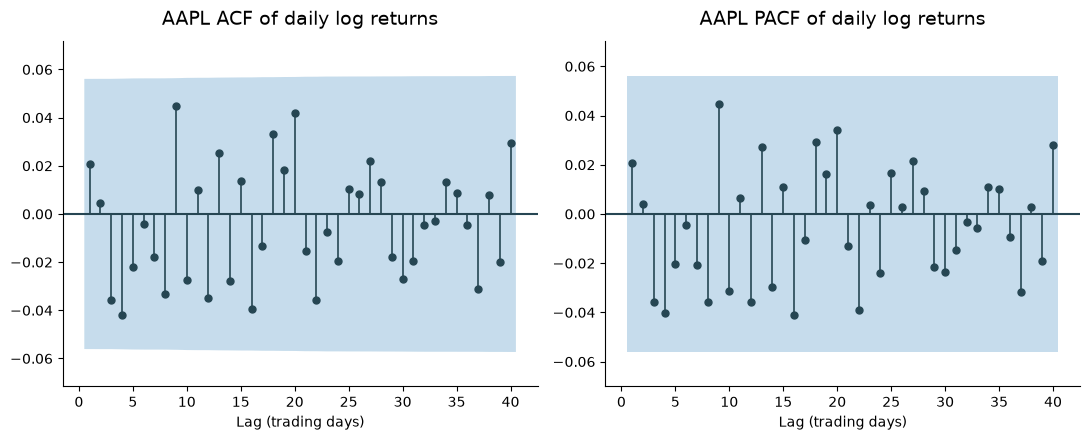

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
stem = {"colors": "#264653", "linewidth": 1.2}

plot_acf(
    log_returns,
    lags=40,
    ax=axes[0],
    zero=False,
    auto_ylims=True,
    title=f"{ticker} ACF of daily log returns",
    color="#264653",
    vlines_kwargs=stem,
)
plot_pacf(
    log_returns,
    lags=40,
    ax=axes[1],
    method="ywm",
    zero=False,
    auto_ylims=True,
    title=f"{ticker} PACF of daily log returns",
    color="#264653",
    vlines_kwargs=stem,
)
for ax in axes:
    ax.set_title(ax.get_title(), fontsize=14, pad=12)
    ax.set_xlabel("Lag (trading days)")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.tight_layout()
plt.show()

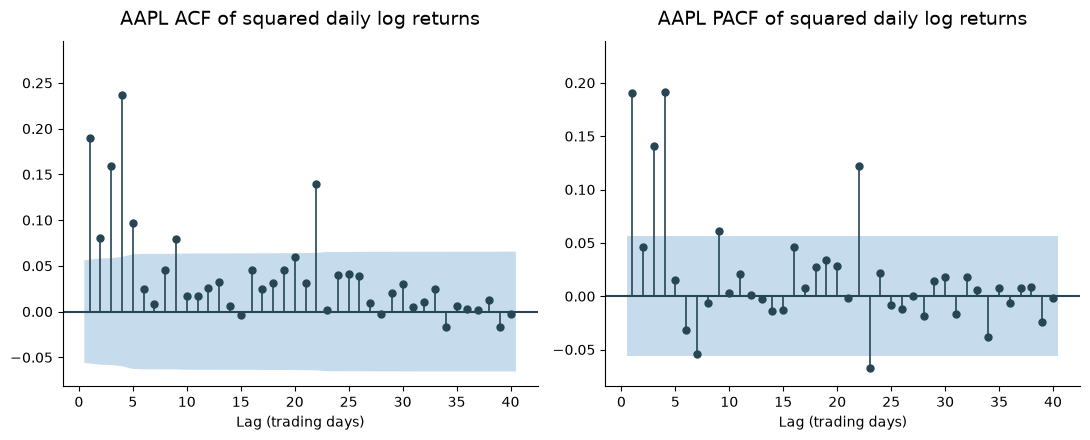

In [23]:
squared_returns = log_returns**2

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
stem = {"colors": "#264653", "linewidth": 1.2}

plot_acf(
    squared_returns,
    lags=40,
    ax=axes[0],
    zero=False,
    auto_ylims=True,
    title=f"{ticker} ACF of squared daily log returns",
    color="#264653",
    vlines_kwargs=stem,
)
plot_pacf(
    squared_returns,
    lags=40,
    ax=axes[1],
    method="ywm",
    zero=False,
    auto_ylims=True,
    title=f"{ticker} PACF of squared daily log returns",
    color="#264653",
    vlines_kwargs=stem,
)
for ax in axes:
    ax.set_title(ax.get_title(), fontsize=14, pad=12)
    ax.set_xlabel("Lag (trading days)")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.tight_layout()
plt.show()

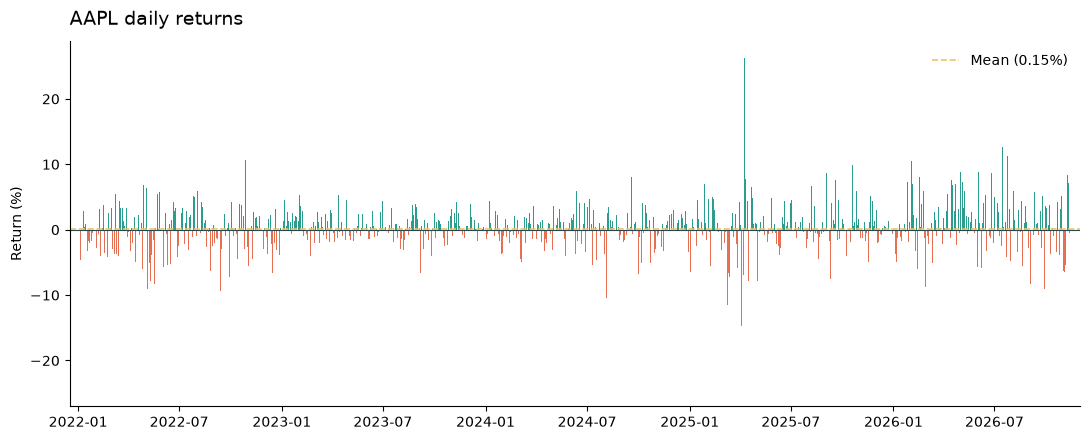

In [24]:
fig, ax = plt.subplots(figsize=(11, 4.5))

colors = np.where(diff_prices.to_numpy() >= 0, "#2a9d8f", "#e76f51")
ax.bar(returns.index, diff_prices, color=colors, width=1.0, linewidth=0)
ax.axhline(0, color="#264653", linewidth=0.8)

mean = float(diff_prices.mean())
ax.axhline(
    mean,
    color="#e9c46a",
    linewidth=1.2,
    linestyle="--",
    label=f"Mean ({mean:.2f}%)",
)

ax.set_title(f"{ticker} daily returns", loc="left", fontsize=14, pad=12)
ax.set_ylabel("Return (%)")
ax.legend(frameon=False, loc="upper right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.margins(x=0.01)
fig.tight_layout()
plt.show()

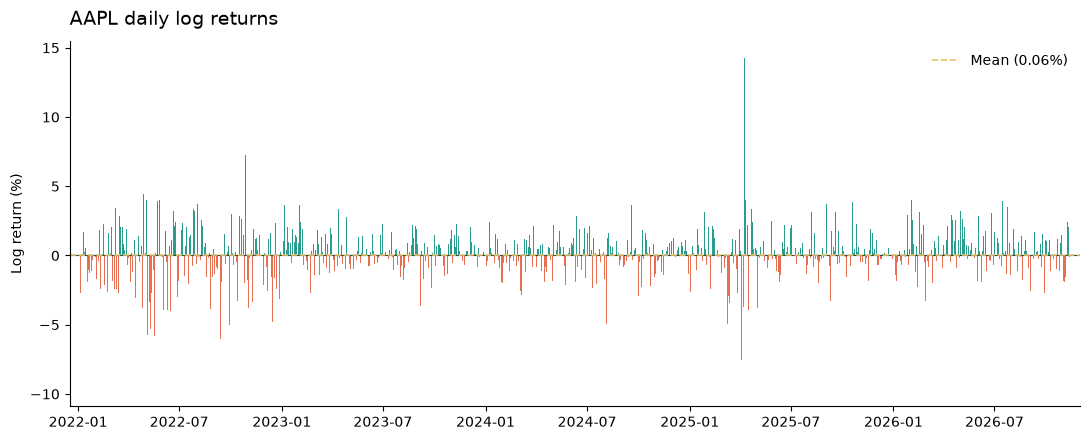

In [25]:
fig, ax = plt.subplots(figsize=(11, 4.5))

colors = np.where(log_returns.to_numpy() >= 0, "#2a9d8f", "#e76f51")
ax.bar(log_returns.index, log_returns, color=colors, width=1.0, linewidth=0)
ax.axhline(0, color="#264653", linewidth=0.8)

mean = float(log_returns.mean())
ax.axhline(
    mean,
    color="#e9c46a",
    linewidth=1.2,
    linestyle="--",
    label=f"Mean ({mean:.2f}%)",
)

ax.set_title(f"{ticker} daily log returns", loc="left", fontsize=14, pad=12)
ax.set_ylabel("Log return (%)")
ax.legend(frameon=False, loc="upper right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.margins(x=0.01)
fig.tight_layout()
plt.show()

                           AR - GARCH Model Results                           
Dep. Variable:                   AAPL   R-squared:                      -0.000
Mean Model:                        AR   Adj. R-squared:                 -0.001
Vol Model:                      GARCH   Log-Likelihood:               -2351.95
Distribution:                  Normal   AIC:                           4713.90
Method:            Maximum Likelihood   BIC:                           4739.44
                                        No. Observations:                 1220
Date:                Sun, Nov 15 2026   Df Residuals:                     1218
Time:                        18:17:24   Df Model:                            2
                                 Mean Model                                
                 coef    std err          t      P>|t|     95.0% Conf. Int.
---------------------------------------------------------------------------
Const          0.0948  4.819e-02      1.967  4.920e-02  [3.30

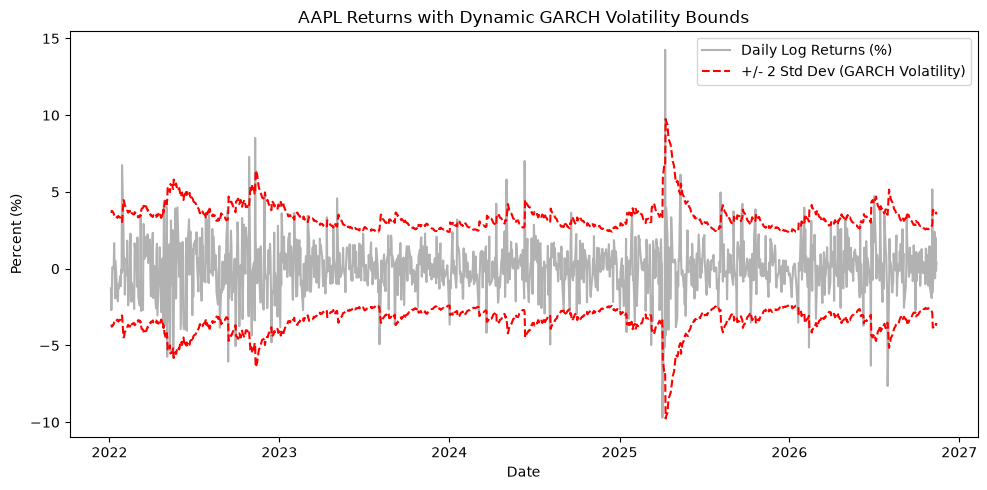


--- AAPL 5-day forecast variance ---
                 h.1      h.2       h.3       h.4       h.5
Date                                                       
2026-11-13  2.934215  2.94167  2.945787  2.949761  2.953598


In [26]:
# 3. Define and fit an ARMA(1,1) + GARCH(1,1) model
# mean='AR', lags=1 specifies an AR(1) mean equation (you can adjust for ARMA)
# vol='Garch', p=1, q=1 specifies a standard GARCH(1,1) volatility equation
model = arch_model(log_returns, mean="AR", lags=1, vol="GARCH", p=1, o=0, q=1, dist="normal")

# Fit the model to the data
results = model.fit(disp="off")

# Print the parameter estimates and summary statistics
print(results.summary())

# 4. Extract the conditional volatility (standard deviation over time)
conditional_volatility = results.conditional_volatility

# 5. Plot the standardized returns alongside the estimated time-varying volatility envelope
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    log_returns.index,
    log_returns,
    color="gray",
    alpha=0.6,
    label="Daily Log Returns (%)",
)
ax.plot(
    conditional_volatility.index,
    2 * conditional_volatility,
    color="red",
    linestyle="--",
    label="+/- 2 Std Dev (GARCH Volatility)",
)
ax.plot(
    conditional_volatility.index,
    -2 * conditional_volatility,
    color="red",
    linestyle="--",
)

ax.set_title(f"{ticker} Returns with Dynamic GARCH Volatility Bounds")
ax.set_xlabel("Date")
ax.set_ylabel("Percent (%)")
ax.legend()
plt.tight_layout()
plt.show()

# 6. Generate multi-step volatility and return forecasts for the next 5 days
forecasts = results.forecast(horizon=5)
print(f"\n--- {ticker} 5-day forecast variance ---")
print(forecasts.variance.dropna().tail(1))

In [ ]:
from scipy import stats

# Refit on the previous two years only, then forecast the next day.
# That day is never inside the fit, so the VaR is out of sample.
window = 504
alpha_levels = (0.05, 0.01)

am = arch_model(log_returns, mean="AR", lags=1, vol="GARCH", p=1, o=0, q=1, dist="normal")
records = []
for i in range(window, len(log_returns)):
    res = am.fit(first_obs=i - window, last_obs=i, disp="off")
    forecast = res.forecast(horizon=1, reindex=False)
    records.append(
        (
            log_returns.index[i],
            float(log_returns.iloc[i]),
            float(forecast.mean.iloc[-1, 0]),
            float(np.sqrt(forecast.variance.iloc[-1, 0])),
        )
    )

backtest = pd.DataFrame(records, columns=["date", "return", "mu", "sigma"]).set_index("date")

rows = []
for alpha in alpha_levels:
    threshold = backtest["mu"] + stats.norm.ppf(alpha) * backtest["sigma"]
    breaches = backtest["return"] < threshold
    n = len(backtest)
    hits = int(breaches.sum())
    rate = hits / n
    if 0 < hits < n:
        ll_null = (n - hits) * np.log(1 - alpha) + hits * np.log(alpha)
        ll_alt = (n - hits) * np.log(1 - rate) + hits * np.log(rate)
        lr_stat = -2 * (ll_null - ll_alt)
        kupiec_p = float(stats.chi2.sf(lr_stat, df=1))
    else:
        kupiec_p = np.nan
    level = int(round((1 - alpha) * 100))
    backtest[f"var_{level}"] = threshold
    backtest[f"breach_{level}"] = breaches
    rows.append((f"{level}%", alpha * n, hits, rate, kupiec_p))

print(f"{ticker}: {len(backtest)} one-day forecasts, each fit on the previous {window} days")
print(f"{'VaR':>6} {'expected':>10} {'breaches':>10} {'rate':>8} {'Kupiec p':>10}")
for level, expected, hits, rate, kupiec_p in rows:
    print(f"{level:>6} {expected:10.1f} {hits:10d} {rate:8.1%} {kupiec_p:10.3f}")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(backtest.index, backtest["return"], color="#264653", linewidth=0.8, alpha=0.75, label="Log return")
ax.plot(backtest.index, backtest["var_95"], color="#e9c46a", linewidth=1.2, label="95% VaR")
ax.plot(backtest.index, backtest["var_99"], color="#e76f51", linewidth=1.0, linestyle="--", label="99% VaR")
hits = backtest.loc[backtest["breach_95"]]
ax.scatter(hits.index, hits["return"], color="#e76f51", s=16, zorder=3, label="95% breach")
ax.set_title(f"{ticker} one-day-ahead VaR", loc="left", fontsize=14, pad=12)
ax.set_ylabel("Log return (%)")
ax.legend(frameon=False, ncol=2, loc="lower left")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()